# EDA
## Dataset du Titanic

Le fichier visé est la version `titanic.csv` du dépôt de données d'exemple de Seaborn.

### Description des colonnes

| Colonne | Type | Description |
|---|---|---|
| `survived` | binaire (0/1) | Survie du passager : `0` = décédé, `1` = survivant. **Variable cible** de l'analyse. |
| `pclass` | catégorielle ordinale (1, 2, 3) | Classe du billet : `1` = première, `2` = deuxième, `3` = troisième. Indicateur du statut socio-économique. |
| `sex` | catégorielle | Sexe du passager : `male` ou `female`. |
| `age` | numérique continue | Âge en années (fractionnaire pour les enfants de moins d'un an). Contient des valeurs manquantes. |
| `sibsp` | numérique discrète | Nombre de frères, sœurs ou conjoints (*siblings / spouses*) à bord. |
| `parch` | numérique discrète | Nombre de parents ou d'enfants (*parents / children*) à bord. |
| `fare` | numérique continue | Prix du billet payé (en livres sterling de l'époque). |
| `embarked` | catégorielle | Code du port d'embarquement : `C` = Cherbourg, `Q` = Queenstown, `S` = Southampton. |
| `class` | catégorielle | Même information que `pclass`, sous forme de texte : `First`, `Second`, `Third`. |
| `who` | catégorielle | Catégorie de personne : `man`, `woman` ou `child`. |
| `adult_male` | booléenne | `True` si le passager est un homme adulte, sinon `False`. |
| `deck` | catégorielle | Pont de la cabine (`A` à `G`). Très majoritairement manquante. |
| `embark_town` | catégorielle | Nom du port d'embarquement : `Cherbourg`, `Queenstown` ou `Southampton` (équivalent textuel de `embarked`). |
| `alive` | catégorielle | Même information que `survived`, sous forme de texte : `yes` ou `no`. |
| `alone` | booléenne | `True` si le passager voyageait seul (`sibsp` = 0 et `parch` = 0), sinon `False`. |


> Les colonnes `class`, `embark_town` et `alive` sont **redondantes** avec `pclass`, `embarked` et `survived` : elles n'apportent pas d'information supplémentaire.

### Problématique

> **Quels facteurs semblent associés à la survie des passagers du Titanic ?**


# 1. Importation des bibliothèques

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from ipywidgets import interact
    WIDGETS_DISPONIBLES = True
except ImportError:
    WIDGETS_DISPONIBLES = False
    print("ipywidgets n'est pas installé dans cet environnement.")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")


ipywidgets n'est pas installé dans cet environnement.


# 2. Chargement des données

In [ ]:
df = pd.read_csv("../data/raw/titanic.csv")
df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.000,1,0,7.250,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.000,1,0,71.283,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.000,0,0,7.925,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.000,1,0,53.100,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.000,0,0,8.050,S,Third,man,True,NaN,Southampton,no,True


### Résultat attendu

Le jeu de données contient **891 passagers et 15 variables**.

Colonnes attendues :

```text
survived, pclass, sex, age, sibsp, parch, fare, embarked,
class, who, adult_male, deck, embark_town, alive, alone
```


# 3. Exploration initiale

In [3]:
print("Dimensions :", df.shape)

print("\nTypes :")
print(df.dtypes)

print("\nValeurs manquantes :")
print(df.isna().sum())

print("\nDoublons complets :", df.duplicated().sum())

df.describe(include="all").T


Dimensions : (891, 15)

Types :
survived         int64
pclass           int64
sex                str
age            float64
sibsp            int64
parch            int64
fare           float64
embarked           str
class              str
who                str
adult_male        bool
deck               str
embark_town        str
alive              str
alone             bool
dtype: object

Valeurs manquantes :
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Doublons complets : 107


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.000,NaN,NaN,NaN,0.384,0.487,0.000,0.000,0.000,1.000,1.000
pclass,891.000,NaN,NaN,NaN,2.309,0.836,1.000,2.000,3.000,3.000,3.000
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.000,NaN,NaN,NaN,29.699,14.526,0.420,20.125,28.000,38.000,80.000
sibsp,891.000,NaN,NaN,NaN,0.523,1.103,0.000,0.000,0.000,1.000,8.000
parch,891.000,NaN,NaN,NaN,0.382,0.806,0.000,0.000,0.000,0.000,6.000
fare,891.000,NaN,NaN,NaN,32.204,49.693,0.000,7.910,14.454,31.000,512.329
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Explication attendue

Les valeurs manquantes les plus importantes sont :

- `age` : **177 valeurs manquantes** ;
- `deck` : **688 valeurs manquantes** ;
- `embarked` : **2 valeurs manquantes** ;
- `embark_town` : **2 valeurs manquantes**.

`deck` est donc manquante pour environ **77 %** des passagers. Pour un laboratoire d'introduction, il est raisonnable de ne pas l'utiliser dans la suite de l'analyse.

`pclass` est stockée sous forme numérique, mais représente une **catégorie ordinale**, pas une mesure continue.


# 4. Nettoyage et préparation

## 4.1 Traitement de `age`

Une solution simple et robuste est de remplacer les âges manquants par la **médiane**.

Une amélioration possible serait d'utiliser une médiane par sous-groupe (`sex`, `class`, etc.), mais cela dépasse ce qui est nécessaire dans ce laboratoire.


In [4]:
age_mediane = df["age"].median()
print("Médiane de l'âge :", age_mediane)

df["age"] = df["age"].fillna(age_mediane)

print("Valeurs manquantes restantes dans age :", df["age"].isna().sum())


Médiane de l'âge : 28.0
Valeurs manquantes restantes dans age : 0


### Pourquoi la médiane ?

La médiane est moins influencée que la moyenne par les âges extrêmes.

On évite aussi de supprimer 177 passagers, ce qui représenterait une perte importante d'information.


## 4.2 Traitement de `embarked` et `embark_town`

Comme seulement deux valeurs sont manquantes, on peut utiliser le **mode** (valeur la plus fréquente).


In [5]:
mode_embarked = df["embarked"].mode()[0]
mode_town = df["embark_town"].mode()[0]

df["embarked"] = df["embarked"].fillna(mode_embarked)
df["embark_town"] = df["embark_town"].fillna(mode_town)

print(mode_embarked, mode_town)


S Southampton


## 4.3 Décision concernant `deck`

In [6]:
taux_manquant_deck = df["deck"].isna().mean() * 100
print(f"Valeurs manquantes dans deck : {taux_manquant_deck:.1f} %")


Valeurs manquantes dans deck : 77.2 %


### Décision exemplaire

On peut retirer `deck` du DataFrame utilisé pour ce laboratoire, car près de quatre valeurs sur cinq sont manquantes.

```python
df = df.drop(columns=["deck"])
```

Ce choix n'est pas universel : dans une autre étude, on pourrait transformer l'information en une variable indiquant simplement si une cabine est connue ou non.


In [7]:
df = df.drop(columns=["deck"])


# 5. Création de nouvelles variables

In [8]:
df["family_size"] = df["sibsp"] + df["parch"] + 1

bins = [0, 12, 17, 59, np.inf]
labels = ["Enfant", "Adolescent", "Adulte", "Aîné"]

df["age_group"] = pd.cut(
    df["age"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

df[["age", "sibsp", "parch", "family_size", "age_group"]].head()


,age,sibsp,parch,family_size,age_group
0,22.000,1,0,2,Adulte
1,38.000,1,0,2,Adulte
2,26.000,0,0,1,Adulte
3,35.000,1,0,2,Adulte
4,35.000,0,0,1,Adulte


### Explication

`family_size` combine deux variables déjà présentes et facilite l'analyse de la composition familiale.

`age_group` transforme une variable continue en catégories interprétables. Cette simplification entraîne une perte de précision, mais elle facilite les comparaisons.


# 6. Statistiques descriptives

In [9]:
df[["age", "fare", "family_size"]].describe().T


,count,mean,std,min,25%,50%,75%,max
age,891.000,29.362,13.020,0.420,22.000,28.000,35.000,80.000
fare,891.000,32.204,49.693,0.000,7.910,14.454,31.000,512.329
family_size,891.000,1.905,1.613,1.000,1.000,1.000,2.000,11.000


## Résultats de référence

Avant imputation, l'âge a environ :

- moyenne : **29,7 ans** ;
- médiane : **28 ans** ;
- minimum : **0,42 an** ;
- maximum : **80 ans**.

Pour `fare` :

- moyenne : environ **32,20** ;
- médiane : environ **14,45** ;
- maximum : environ **512,33**.

Le tarif est donc très asymétrique vers la droite : quelques tarifs très élevés font augmenter fortement la moyenne.


# 7. Analyse par groupes

## 7.1 Survie selon le sexe

In [10]:
survie_sexe = df.groupby("sex")["survived"].agg(["mean", "count", "sum"])
survie_sexe


,mean,count,sum
sex,,,
female,0.742,314,233
male,0.189,577,109


### Interprétation

Taux de survie de référence :

- femmes : environ **74,2 %** ;
- hommes : environ **18,9 %**.

L'écart est très important. Le sexe est fortement associé au statut de survie dans ce jeu de données.


## 7.2 Survie selon la classe

In [11]:
survie_classe = df.groupby("class", observed=False)["survived"].agg(["mean", "count", "sum"])
survie_classe


,mean,count,sum
class,,,
First,0.630,216,136
Second,0.473,184,87
Third,0.242,491,119


### Interprétation

Taux de survie approximatifs :

- First : **63,0 %** ;
- Second : **47,3 %** ;
- Third : **24,2 %**.

La survie diminue fortement lorsque l'on passe de la première à la troisième classe.


## 7.3 Survie selon la catégorie d'âge

In [12]:
survie_age = df.groupby("age_group", observed=False)["survived"].agg(["mean", "count", "sum"])
survie_age


,mean,count,sum
age_group,,,
Enfant,0.580,69,40
Adolescent,0.477,44,21
Adulte,0.364,752,274
Aîné,0.269,26,7


### Interprétation

Les groupes d'âge peuvent présenter des différences, mais il faut être prudent : `age_group` dépend ici d'une variable `age` dont certaines valeurs ont été imputées.

Les résultats doivent donc être lus comme une exploration, pas comme une preuve causale.


# 8. Filtrage

## 8.1 Femmes de troisième classe

In [13]:
femmes_3e = df[(df["sex"] == "female") & (df["pclass"] == 3)]

print("Nombre :", len(femmes_3e))
print("Taux de survie :", femmes_3e["survived"].mean())
femmes_3e.head()


Nombre : 144
Taux de survie : 0.5


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,family_size,age_group
2,1,3,female,26.000,0,0,7.925,S,Third,woman,False,Southampton,yes,True,1,Adulte
8,1,3,female,27.000,0,2,11.133,S,Third,woman,False,Southampton,yes,False,3,Adulte
10,1,3,female,4.000,1,1,16.700,S,Third,child,False,Southampton,yes,False,3,Enfant
14,0,3,female,14.000,0,0,7.854,S,Third,child,False,Southampton,no,True,1,Adolescent
18,0,3,female,31.000,1,0,18.000,S,Third,woman,False,Southampton,no,False,2,Adulte


## 8.2 Hommes de première classe

In [14]:
hommes_1re = df[(df["sex"] == "male") & (df["pclass"] == 1)]

print("Nombre :", len(hommes_1re))
print("Taux de survie :", hommes_1re["survived"].mean())
hommes_1re.head()


Nombre : 122
Taux de survie : 0.36885245901639346


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,family_size,age_group
6,0,1,male,54.000,0,0,51.862,S,First,man,True,Southampton,no,True,1,Adulte
23,1,1,male,28.000,0,0,35.500,S,First,man,True,Southampton,yes,True,1,Adulte
27,0,1,male,19.000,3,2,263.000,S,First,man,True,Southampton,no,False,6,Adulte
30,0,1,male,40.000,0,0,27.721,C,First,man,True,Cherbourg,no,True,1,Adulte
34,0,1,male,28.000,1,0,82.171,C,First,man,True,Cherbourg,no,False,2,Adulte


## 8.3 Enfants de moins de 13 ans

In [15]:
enfants = df[df["age"] < 13]

print("Nombre :", len(enfants))
print("Taux de survie :", enfants["survived"].mean())
enfants.head()


Nombre : 69
Taux de survie : 0.5797101449275363


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,family_size,age_group
7,0,3,male,2.000,3,1,21.075,S,Third,child,False,Southampton,no,False,5,Enfant
10,1,3,female,4.000,1,1,16.700,S,Third,child,False,Southampton,yes,False,3,Enfant
16,0,3,male,2.000,4,1,29.125,Q,Third,child,False,Queenstown,no,False,6,Enfant
24,0,3,female,8.000,3,1,21.075,S,Third,child,False,Southampton,no,False,5,Enfant
43,1,2,female,3.000,1,2,41.579,C,Second,child,False,Cherbourg,yes,False,4,Enfant


### Pourquoi un filtre ?

Les filtres montrent pourquoi une EDA ne devrait pas se limiter à une seule variable.

Par exemple, la classe et le sexe sont tous deux associés à la survie. Leur combinaison permet de mettre en évidence des profils différents à l'intérieur d'une même classe.


# 9. Valeurs atypiques — `fare`

In [16]:
q1 = df["fare"].quantile(0.25)
q3 = df["fare"].quantile(0.75)
iqr = q3 - q1

borne_inf = q1 - 1.5 * iqr
borne_sup = q3 + 1.5 * iqr

print("Q1 :", q1)
print("Q3 :", q3)
print("IQR :", iqr)
print("Borne inférieure :", borne_inf)
print("Borne supérieure :", borne_sup)


Q1 : 7.9104
Q3 : 31.0
IQR : 23.0896
Borne inférieure : -26.724
Borne supérieure : 65.6344


In [17]:
fare_outliers = df[
    (df["fare"] < borne_inf) |
    (df["fare"] > borne_sup)
]

print("Nombre d'observations atypiques :", len(fare_outliers))
fare_outliers[["pclass", "sex", "age", "fare", "survived"]].sort_values(
    "fare", ascending=False
).head(20)


Nombre d'observations atypiques : 116


,pclass,sex,age,fare,survived
258,1,female,35.000,512.329,1
737,1,male,35.000,512.329,1
679,1,male,36.000,512.329,1
27,1,male,19.000,263.000,0
341,1,female,24.000,263.000,1
438,1,male,64.000,263.000,0
88,1,female,23.000,263.000,1
311,1,female,18.000,262.375,1
742,1,female,21.000,262.375,1
299,1,female,50.000,247.521,1


## Résultats et interprétation

Valeurs de référence approximatives :

- Q1 : **7,91** ;
- Q3 : **31,00** ;
- IQR : **23,09** ;
- borne supérieure : environ **65,63**.

Un tarif supérieur à cette borne est statistiquement atypique selon l'IQR.

Il ne faut cependant pas le supprimer automatiquement. Les passagers de première classe pouvaient réellement payer des tarifs beaucoup plus élevés. L'outlier peut donc représenter une caractéristique réelle du phénomène étudié.


# 10. Corrélations

In [18]:
variables_corr = [
    "survived",
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare",
    "family_size"
]

corr = df[variables_corr].corr()
corr


,survived,pclass,age,sibsp,parch,fare,family_size
survived,1.000,-0.338,-0.065,-0.035,0.082,0.257,0.017
pclass,-0.338,1.000,-0.340,0.083,0.018,-0.549,0.066
age,-0.065,-0.340,1.000,-0.233,-0.172,0.097,-0.246
sibsp,-0.035,0.083,-0.233,1.000,0.415,0.160,0.891
parch,0.082,0.018,-0.172,0.415,1.000,0.216,0.783
fare,0.257,-0.549,0.097,0.160,0.216,1.000,0.217
family_size,0.017,0.066,-0.246,0.891,0.783,0.217,1.000


In [19]:
corr["survived"].sort_values(ascending=False)


survived       1.000
fare           0.257
parch          0.082
family_size    0.017
sibsp         -0.035
age           -0.065
pclass        -0.338
Name: survived, dtype: float64

## Interprétation de référence

Sur les variables numériques d'origine, on observe notamment :

- `fare` ↔ `survived` : corrélation positive d'environ **+0,26** ;
- `pclass` ↔ `survived` : corrélation négative d'environ **-0,34** ;
- `age` ↔ `survived` : relation linéaire faible.

Attention : `pclass` est une catégorie ordinale codée par 1, 2 et 3. Une corrélation numérique sur cette variable doit donc être interprétée avec prudence.


# 11. Visualisations

## 11.1 Taux de survie selon le sexe

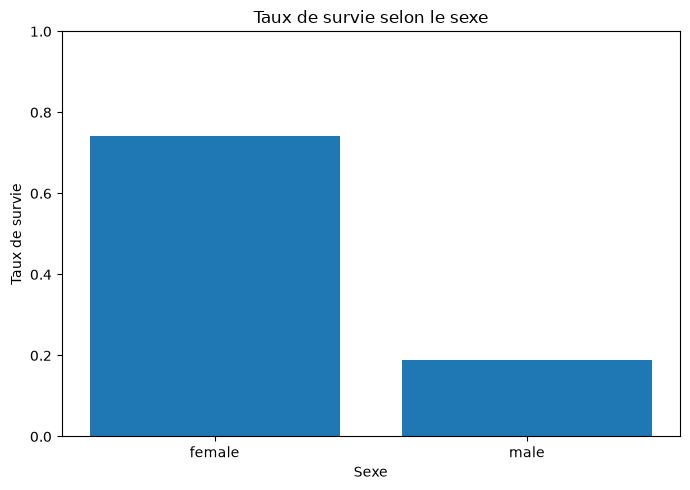

In [20]:
survie_sexe = df.groupby("sex")["survived"].mean()

plt.figure(figsize=(7, 5))
plt.bar(survie_sexe.index, survie_sexe.values)
plt.title("Taux de survie selon le sexe")
plt.xlabel("Sexe")
plt.ylabel("Taux de survie")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


### Interprétation

Le taux de survie des femmes est nettement supérieur à celui des hommes. C'est l'un des écarts les plus marqués observés dans le jeu de données.


## 11.2 Taux de survie selon la classe

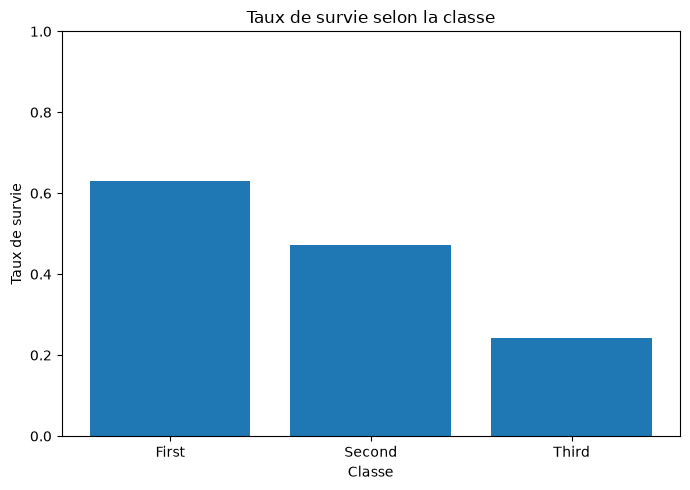

In [21]:
survie_classe = df.groupby("class", observed=False)["survived"].mean()

plt.figure(figsize=(7, 5))
plt.bar(survie_classe.index.astype(str), survie_classe.values)
plt.title("Taux de survie selon la classe")
plt.xlabel("Classe")
plt.ylabel("Taux de survie")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


### Interprétation

La première classe présente le taux de survie le plus élevé et la troisième le plus faible. La classe est donc fortement associée à la survie.


## 11.3 Distribution de l'âge

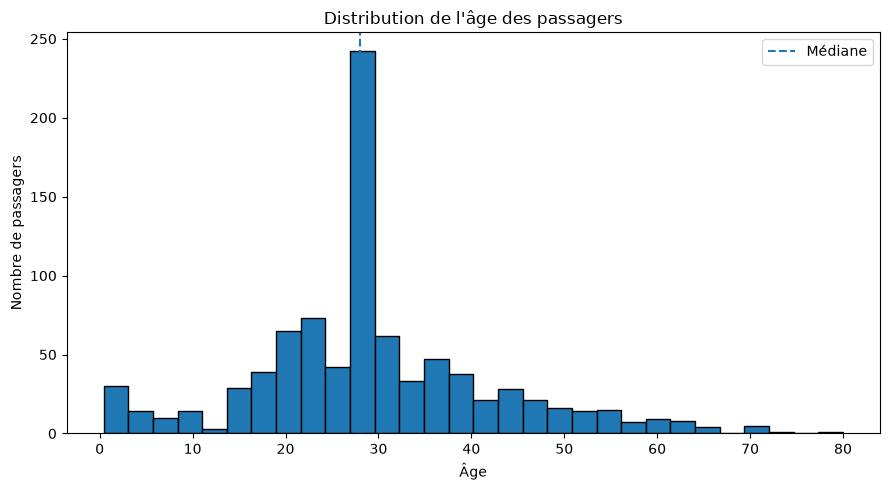

In [22]:
plt.figure(figsize=(9, 5))
plt.hist(df["age"], bins=30, edgecolor="black")
plt.axvline(df["age"].median(), linestyle="--", label="Médiane")
plt.title("Distribution de l'âge des passagers")
plt.xlabel("Âge")
plt.ylabel("Nombre de passagers")
plt.legend()
plt.tight_layout()
plt.show()


### Interprétation

La majorité des passagers sont des adultes jeunes ou d'âge moyen. Il faut garder à l'esprit que les âges manquants ont été remplacés par la médiane, ce qui peut créer une concentration artificielle autour de cette valeur.


## 11.4 Âge, tarif et survie

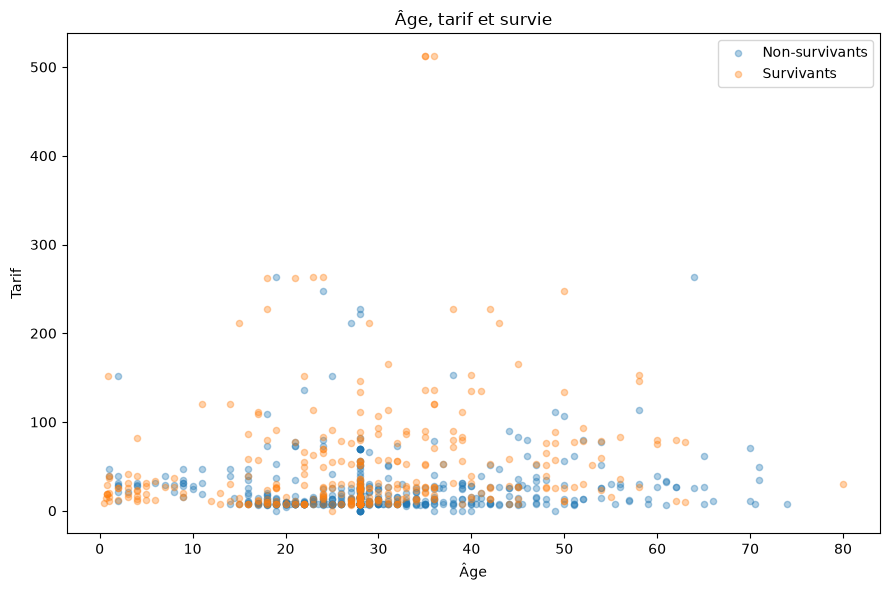

In [23]:
survivants = df[df["survived"] == 1]
non_survivants = df[df["survived"] == 0]

plt.figure(figsize=(9, 6))
plt.scatter(
    non_survivants["age"],
    non_survivants["fare"],
    alpha=0.35,
    s=20,
    label="Non-survivants"
)
plt.scatter(
    survivants["age"],
    survivants["fare"],
    alpha=0.35,
    s=20,
    label="Survivants"
)

plt.title("Âge, tarif et survie")
plt.xlabel("Âge")
plt.ylabel("Tarif")
plt.legend()
plt.tight_layout()
plt.show()


### Interprétation

Les survivants ne forment pas un groupe parfaitement séparé selon l'âge et le tarif. Les tarifs élevés sont davantage associés aux classes supérieures, elles-mêmes associées à une meilleure survie.

Ce graphique illustre pourquoi on doit éviter de conclure que le tarif **cause** la survie.


# 12. Visualisation interactive

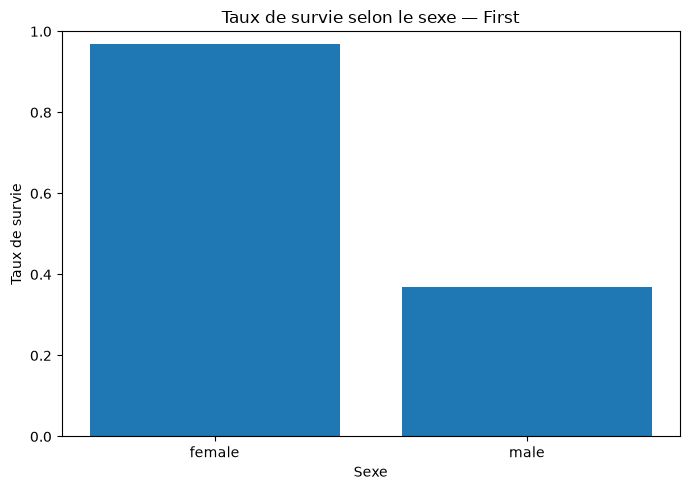

In [24]:
def survie_par_sexe_et_classe(classe):
    donnees = df[df["class"] == classe]
    taux = donnees.groupby("sex")["survived"].mean()

    plt.figure(figsize=(7, 5))
    plt.bar(taux.index, taux.values)
    plt.title(f"Taux de survie selon le sexe — {classe}")
    plt.xlabel("Sexe")
    plt.ylabel("Taux de survie")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

if WIDGETS_DISPONIBLES:
    interact(
        survie_par_sexe_et_classe,
        classe=["First", "Second", "Third"]
    )
else:
    survie_par_sexe_et_classe("First")


### Utilité de l'interactivité

Le même graphique peut être exploré pour plusieurs sous-groupes sans dupliquer le code.

L'utilisateur peut ainsi vérifier rapidement si la différence entre femmes et hommes reste visible dans chacune des classes.


# 13. Mini-synthèse

### 1. Le sexe semble-t-il associé à la survie ?

Oui. Le taux de survie des femmes est beaucoup plus élevé que celui des hommes.

### 2. La classe semble-t-elle associée à la survie ?

Oui. La première classe présente le taux de survie le plus élevé, tandis que la troisième présente le plus faible.

### 3. Les enfants semblent-ils présenter un profil différent ?

Les enfants présentent un profil de survie différent de celui de nombreux adultes, mais l'interprétation doit tenir compte du sexe, de la classe et de la taille des sous-groupes.

### 4. Le tarif payé suffit-il à expliquer la survie ?

Non. Le tarif est associé à la survie, mais il est aussi fortement lié à la classe. Il ne peut donc pas être interprété isolément.

### 5. Principal constat

La survie semble être associée simultanément à plusieurs caractéristiques, particulièrement le sexe et la classe. Une EDA permet d'identifier ces relations, mais ne permet pas d'établir à elle seule les causes des différences observées.


# 14. Conclusion exemplaire

L'analyse exploratoire montre des écarts importants de survie entre différents groupes de passagers. Le sexe est fortement associé à la survie, les femmes présentant un taux beaucoup plus élevé que les hommes. La classe est également importante : les passagers de première classe survivent proportionnellement davantage que ceux de troisième classe. Le tarif présente une association positive avec la survie, mais il est aussi lié à la classe et ne doit donc pas être interprété comme une cause directe. L'analyse est limitée par les valeurs manquantes, particulièrement pour l'âge et le pont (`deck`), ainsi que par l'absence de certaines informations contextuelles. Une analyse supplémentaire pourrait étudier simultanément sexe, classe, âge et composition familiale afin de mieux comprendre leurs interactions.


# Résultats de référence rapides

| Élément | Résultat attendu |
|---|---:|
| Nombre de lignes | 891 |
| Nombre de colonnes | 15 |
| `age` manquant | 177 |
| `deck` manquant | 688 |
| `embarked` manquant | 2 |
| Survivants | 342 |
| Non-survivants | 549 |
| Taux global de survie | ~38,4 % |
| Survie femmes | ~74,2 % |
| Survie hommes | ~18,9 % |
| Survie 1re classe | ~63,0 % |
| Survie 2e classe | ~47,3 % |
| Survie 3e classe | ~24,2 % |
| Âge médian | 28 ans |
| Tarif médian | ~14,45 |
| Tarif maximum | ~512,33 |
| Corrélation `fare` / `survived` | ~+0,26 |
| Corrélation `pclass` / `survived` | ~-0,34 |
